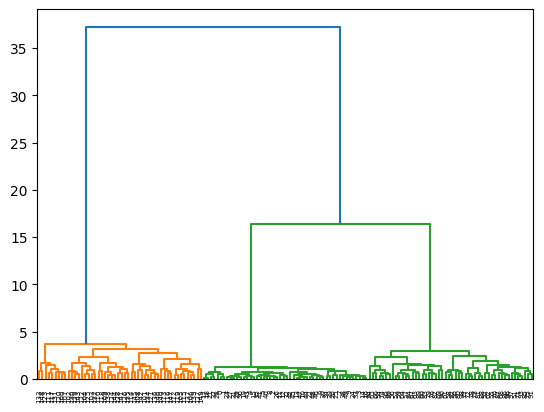

Cluster
2    50
3    50
1    50
Name: count, dtype: int64
                Fresh          Milk       Grocery        Frozen  \
Cluster                                                           
1        29959.920781  29588.556263  29432.097000  29991.679883   
2         5158.503694   5101.292094   5197.797947   4895.279419   
3        14681.101775  15571.878016  15029.911604  15202.878801   

         Detergents_Paper    Delicassen  
Cluster                                  
1            30397.981086  30245.927225  
2             5158.862287   5157.863132  
3            15265.447599  15266.231120  
Silhouette Score: 0.6844266979096454


In [1]:
#Dataset hint: make the 6 spending columns by stacking 3 blocks of random normal numbers, each block with a different mean (small, medium, large spenders). That gives 3 clear groups of 50 customers.
# Hierarchical Clustering: Ward linkage + Euclidean distance. Data is scaled first; dendrogram shows merges, cut gives clusters.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

np.random.seed(1)
cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
data = np.vstack([np.random.normal(5000, 1500, (50, 6)),
                  np.random.normal(15000, 3000, (50, 6)),
                  np.random.normal(30000, 4000, (50, 6))])
df = pd.DataFrame(data, columns=cols)

X = StandardScaler().fit_transform(df)

Z = linkage(X, method="ward", metric="euclidean")
dendrogram(Z)
plt.show()

df["Cluster"] = fcluster(Z, 3, criterion="maxclust")

print(df["Cluster"].value_counts())
print(df.groupby("Cluster").mean())
print("Silhouette Score:", silhouette_score(X, df["Cluster"]))